In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
import yfinance as yf


In [2]:
nifty=yf.download('^NSEI',start='2015-01-01',end='2026-01-01',interval='1d')
nifty.head()

/tmp/ipykernel_2751/1143602198.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  nifty=yf.download('^NSEI',start='2015-01-01',end='2026-01-01',interval='1d')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
Date,,,,,
2015-01-02,8395.450195,8410.599609,8288.700195,8288.700195,101900
2015-01-05,8378.400391,8445.599609,8363.900391,8407.950195,118200
2015-01-06,8127.350098,8327.849609,8111.350098,8325.299805,172800
2015-01-07,8102.100098,8151.200195,8065.450195,8118.649902,164100
2015-01-08,8234.599609,8243.500000,8167.299805,8191.399902,143800


In [3]:
nifty.to_csv("NIFTY50.csv")

In [4]:
nifty.shape,nifty.columns

((2708, 5),
 MultiIndex([( 'Close', '^NSEI'),
             (  'High', '^NSEI'),
             (   'Low', '^NSEI'),
             (  'Open', '^NSEI'),
             ('Volume', '^NSEI')],
            names=['Price', 'Ticker']))

In [5]:
# Reset the index so 'Date' becomes a column instead of the index
nifty = nifty.reset_index()

# Flatten the MultiIndex columns (e.g., ('Close', '^NSEI') becomes 'Close')
nifty.columns = [col[0] if isinstance(col, tuple) else col for col in nifty.columns]

# Ensure the 'Date' column is a datetime object
nifty['Date'] = pd.to_datetime(nifty['Date'])

nifty.head()

,Date,Close,High,Low,Open,Volume
0,2015-01-02,8395.450195,8410.599609,8288.700195,8288.700195,101900
1,2015-01-05,8378.400391,8445.599609,8363.900391,8407.950195,118200
2,2015-01-06,8127.350098,8327.849609,8111.350098,8325.299805,172800
3,2015-01-07,8102.100098,8151.200195,8065.450195,8118.649902,164100
4,2015-01-08,8234.599609,8243.500000,8167.299805,8191.399902,143800


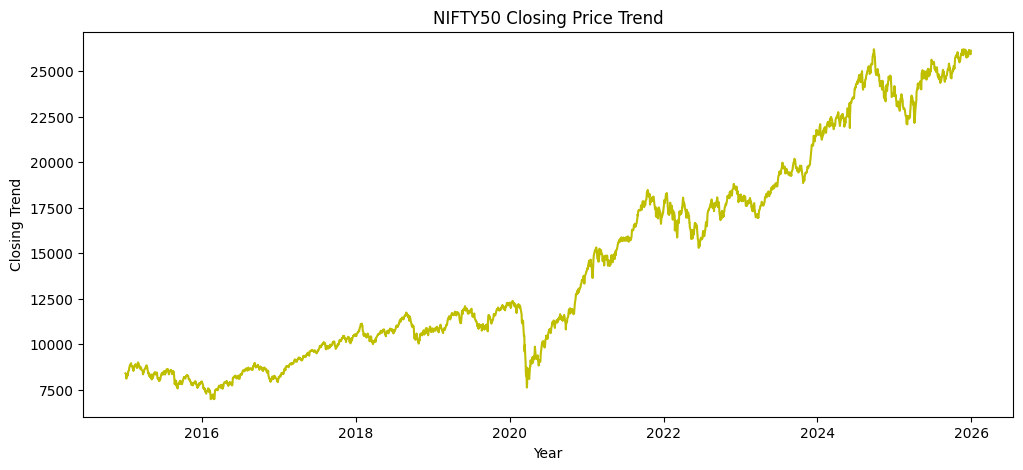

In [6]:
plt.figure(figsize=(12,5))
plt.plot(nifty['Date'],nifty['Close'],c='y')
plt.title('NIFTY50 Closing Price Trend')
plt.xlabel('Year')
plt.ylabel('Closing Trend')
plt.show()

In [7]:
# Calculate daily returns using the formula: (Current Close - Previous Close) / Previous Close
# In Pandas, this can be done easily using .pct_change() or manual shift
nifty['Daily_Return'] = nifty['Close'].pct_change()

# Or calculated manually:
# nifty['Daily_Return'] = (nifty['Close'] - nifty['Close'].shift(1)) / nifty['Close'].shift(1)

nifty[['Date', 'Close', 'Daily_Return']].head()

,Date,Close,Daily_Return
0,2015-01-02,8395.450195,NaN
1,2015-01-05,8378.400391,-0.002031
2,2015-01-06,8127.350098,-0.029964
3,2015-01-07,8102.100098,-0.003107
4,2015-01-08,8234.599609,0.016354


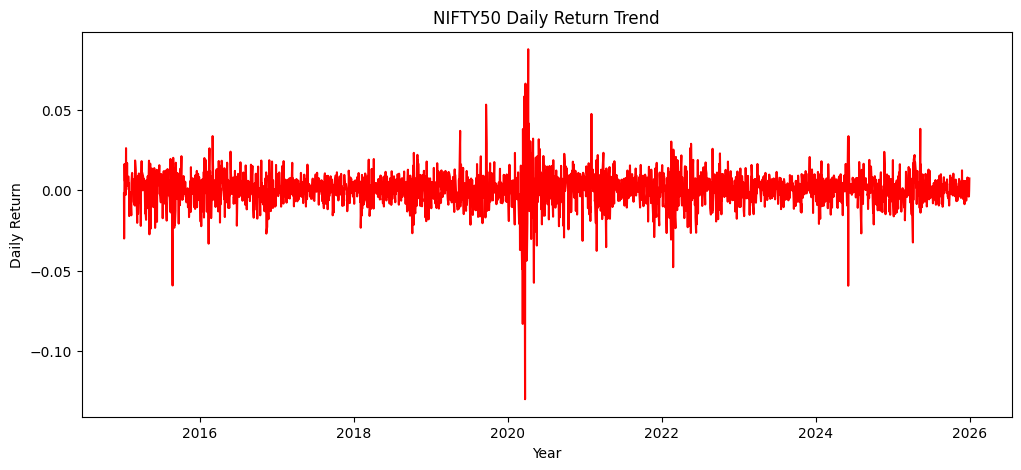

In [8]:
plt.figure(figsize=(12,5))
plt.plot(nifty['Date'],nifty['Daily_Return'],c='r')
plt.title('NIFTY50 Daily Return Trend')
plt.xlabel('Year')
plt.ylabel('Daily Return')
plt.show()

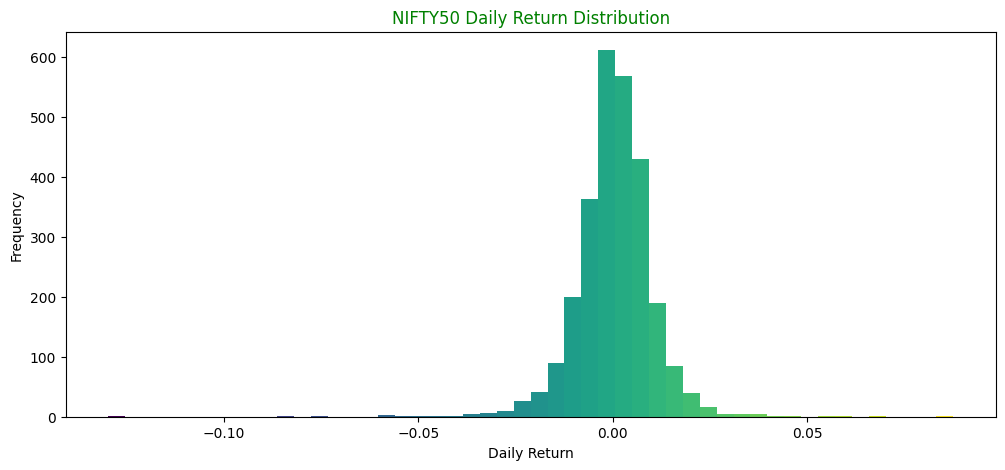

In [9]:
import matplotlib.cm as cm

plt.figure(figsize=(12, 5))

# Drop NaN values first, as plt.hist cannot process them
data = nifty['Daily_Return'].dropna()

# Retrieve the bin values and patches
n, bins, patches = plt.hist(data, bins=50)

# Map each patch to the 'viridis' colormap based on its bin position
bin_centers = 0.5 * (bins[:-1] + bins[1:])
col = (bin_centers - min(bin_centers)) / (max(bin_centers) - min(bin_centers))

for c, p in zip(col, patches):
    plt.setp(p, 'facecolor', cm.viridis(c))

plt.title('NIFTY50 Daily Return Distribution', c='g')
plt.xlabel('Daily Return')
plt.ylabel('Frequency')
plt.show()

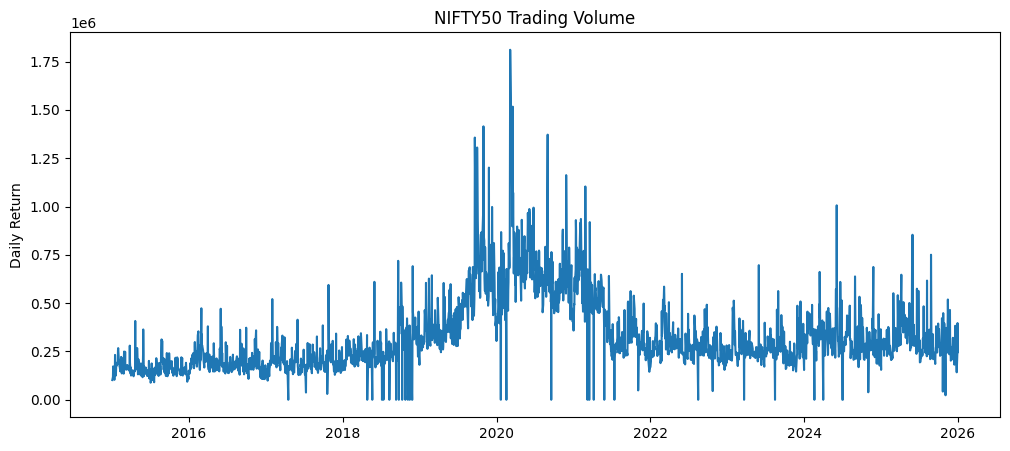

In [10]:
plt.figure(figsize=(12,5))
plt.plot(nifty['Date'],nifty['Volume'])
plt.title('NIFTY50 Trading Volume')
plt.ylabel('Daily Return')
plt.show()

#Simple Moving Average

In [11]:
nifty['SMA_20']=nifty['Close'].rolling(window=20).mean()
nifty['SMA_50']=nifty['Close'].rolling(window=50).mean()
nifty['SMA_100']=nifty['Close'].rolling(window=100).mean()
nifty

,Date,Close,High,Low,Open,Volume,Daily_Return,SMA_20,SMA_50,SMA_100
0,2015-01-02,8395.450195,8410.599609,8288.700195,8288.700195,101900,NaN,NaN,NaN,NaN
1,2015-01-05,8378.400391,8445.599609,8363.900391,8407.950195,118200,-0.002031,NaN,NaN,NaN
2,2015-01-06,8127.350098,8327.849609,8111.350098,8325.299805,172800,-0.029964,NaN,NaN,NaN
3,2015-01-07,8102.100098,8151.200195,8065.450195,8118.649902,164100,-0.003107,NaN,NaN,NaN
4,2015-01-08,8234.599609,8243.500000,8167.299805,8191.399902,143800,0.016354,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2703,2025-12-24,26142.099609,26236.400391,26123.000000,26170.650391,188800,-0.001339,26015.795117,25892.357148,25380.461621
2704,2025-12-26,26042.300781,26144.199219,26008.599609,26121.250000,142200,-0.003818,26007.132617,25910.293164,25393.201133
2705,2025-12-29,25942.099609,26106.800781,25920.300781,26063.349609,234300,-0.003848,25994.090137,25922.664141,25406.968633
2706,2025-12-30,25938.849609,25976.750000,25878.000000,25940.900391,396900,-0.000125,25982.245117,25929.735117,25419.129629


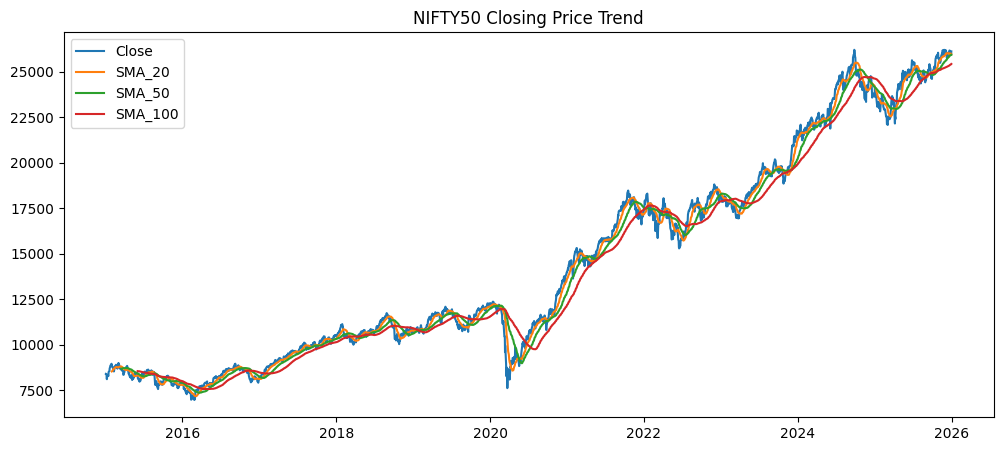

In [12]:
plt.figure(figsize=(12,5))
plt.plot(nifty['Date'],nifty['Close'],label='Close')
plt.plot(nifty['Date'],nifty['SMA_20'],label='SMA_20')
plt.plot(nifty['Date'],nifty['SMA_50'],label='SMA_50')
plt.plot(nifty['Date'],nifty['SMA_100'],label='SMA_100')
plt.title('NIFTY50 Closing Price Trend')
plt.legend()
plt.show()

#EXPONENTIAL MOVING AVERAGE

In [13]:
nifty['EMA_20'] = nifty["Close"].ewm(span=20, adjust=False).mean()
nifty.head()

,Date,Close,High,Low,Open,Volume,Daily_Return,SMA_20,SMA_50,SMA_100,EMA_20
0,2015-01-02,8395.450195,8410.599609,8288.700195,8288.700195,101900,NaN,NaN,NaN,NaN,8395.450195
1,2015-01-05,8378.400391,8445.599609,8363.900391,8407.950195,118200,-0.002031,NaN,NaN,NaN,8393.826404
2,2015-01-06,8127.350098,8327.849609,8111.350098,8325.299805,172800,-0.029964,NaN,NaN,NaN,8368.447709
3,2015-01-07,8102.100098,8151.200195,8065.450195,8118.649902,164100,-0.003107,NaN,NaN,NaN,8343.081269
4,2015-01-08,8234.599609,8243.500000,8167.299805,8191.399902,143800,0.016354,NaN,NaN,NaN,8332.749683


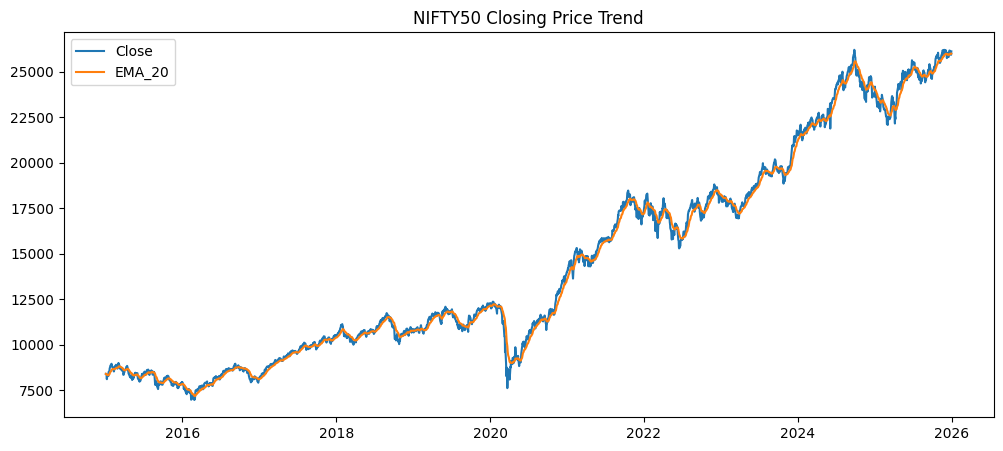

In [14]:
plt.figure(figsize=(12,5))
plt.plot(nifty['Date'],nifty['Close'],label='Close')
plt.plot(nifty['Date'],nifty['EMA_20'],label='EMA_20')
plt.title('NIFTY50 Closing Price Trend')
plt.legend()
plt.show()

#RELATIVE STRENGTH INDEX

In [15]:
delta=nifty['Close'].diff()
gain=delta.where(delta>0,0)
loss=-delta.where(delta<0,0)
avg_gain=gain.rolling(window=14).mean()
avg_loss=loss.rolling(window=14).mean()
rs=avg_gain/avg_loss
rsi=100-(100/(1+rs))
nifty['RSI']=rsi
nifty.head()

,Date,Close,High,Low,Open,Volume,Daily_Return,SMA_20,SMA_50,SMA_100,EMA_20,RSI
0,2015-01-02,8395.450195,8410.599609,8288.700195,8288.700195,101900,NaN,NaN,NaN,NaN,8395.450195,NaN
1,2015-01-05,8378.400391,8445.599609,8363.900391,8407.950195,118200,-0.002031,NaN,NaN,NaN,8393.826404,NaN
2,2015-01-06,8127.350098,8327.849609,8111.350098,8325.299805,172800,-0.029964,NaN,NaN,NaN,8368.447709,NaN
3,2015-01-07,8102.100098,8151.200195,8065.450195,8118.649902,164100,-0.003107,NaN,NaN,NaN,8343.081269,NaN
4,2015-01-08,8234.599609,8243.500000,8167.299805,8191.399902,143800,0.016354,NaN,NaN,NaN,8332.749683,NaN


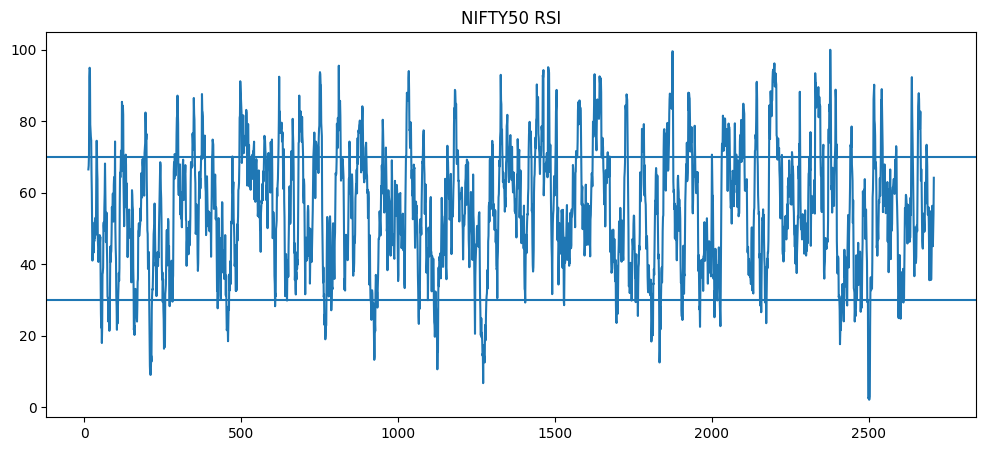

In [16]:
plt.figure(figsize=(12,5))
plt.plot(nifty['RSI'])
plt.axhline(70)
plt.axhline(30)
plt.title('NIFTY50 RSI')
plt.show()

#MACD

In [17]:
ema12=nifty['Close'].ewm(span=12,adjust=False).mean()
ema26=nifty['Close'].ewm(span=26,adjust=False).mean()
nifty['macd']=ema12-ema26

Text(0.5, 1.0, 'MACD indicator')

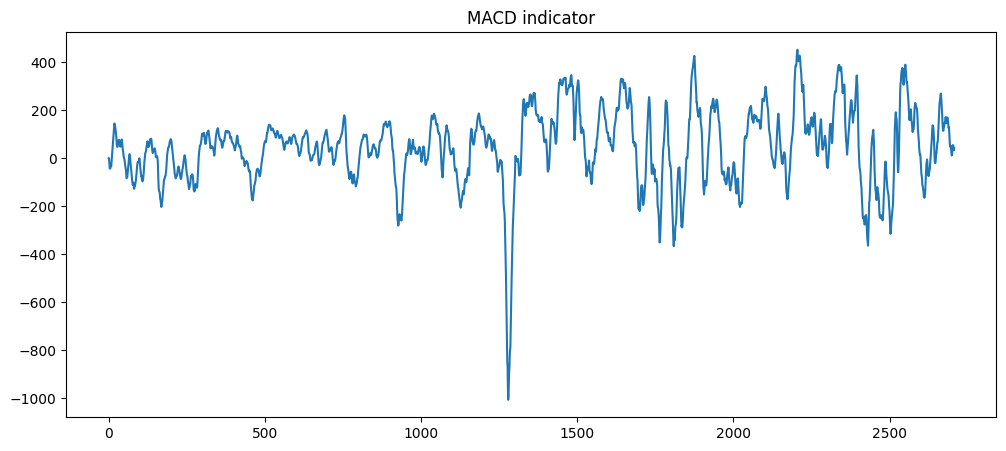

In [18]:
plt.figure(figsize=(12,5))
plt.plot(nifty["macd"])
plt.title("MACD indicator")

In [19]:
nifty.to_csv("nifty50_with_indicators.csv")